<div align="center" style="text-align:center">

<p style="text-align:center;font-size:15px;font-weight:700;color:#283E75;line-height:1.7;margin:0">ĐẠI HỌC QUỐC GIA THÀNH PHỐ HỒ CHÍ MINH<br>TRƯỜNG ĐẠI HỌC KHOA HỌC TỰ NHIÊN<br>KHOA CÔNG NGHỆ THÔNG TIN</p>

<img src="assets/hcmus_logo.png" width="150" style="display:block;margin:12px auto" alt="Logo Trường ĐH Khoa học Tự nhiên">

<p style="text-align:center;font-size:34px;font-weight:700;color:#283E75;margin:8px 0 4px 0">Tổng hợp kết quả</p>
<p style="text-align:center;font-size:18px;color:#3B5BA9;margin:0">Notebook 04 · <i>Coffee Quality with Locations of Origin</i> (Kaggle)</p>

<hr style="border:0;border-top:3px solid #283E75;width:60%;margin:12px auto">

<p style="text-align:center;font-size:17px;font-weight:700;margin:4px 0">CSC17104 — Programming for Data Science</p>
<p style="text-align:center;font-size:15px;margin:0">Đồ án cuối kỳ</p>

<hr style="border:0;border-top:3px solid #283E75;width:60%;margin:12px auto">

<table style="font-size:15px;margin:6px auto 0 auto">
<tr style="background-color:#283E75;color:#ffffff"><th style="padding:6px 14px">MSSV</th><th style="padding:6px 14px">Họ tên</th><th style="padding:6px 14px">Phụ trách</th></tr>
<tr><td style="padding:6px 14px">24120053</td><td style="padding:6px 14px">Đặng Ngọc Hoàng</td><td style="padding:6px 14px">Q1 · Q2 (ML)</td></tr>
<tr style="background-color:#EEF3FB"><td style="padding:6px 14px">23120361</td><td style="padding:6px 14px">Đào Đức Thịnh</td><td style="padding:6px 14px">Q3 · Q4 · Notebook 04</td></tr>
<tr><td style="padding:6px 14px">24120311</td><td style="padding:6px 14px">Nguyễn Mai Tùng Hiếu</td><td style="padding:6px 14px">Q5 · Q6</td></tr>
</table>

</div>

<br>

<div style="background-color:#EEF3FB;border:1px solid #C9D6EE;border-radius:8px;padding:12px 22px;font-size:15.5px;line-height:1.65">

<b style="color:#283E75;font-size:17px;letter-spacing:1px">MỤC LỤC</b>

| <span style="color:#283E75">**0 · Môi trường**</span> | <span style="color:#283E75">**1 · Key findings**</span> | <span style="color:#283E75">**2–4 · Đánh giá**</span> |
|:---|:---|:---|
| Kiểm tra env | 5 insight chính (Q1–Q6) | 2 · Limitations |
| Nạp `apply_style()` | Bảng & biểu đồ tổng hợp ước lượng | 3 · Future work |
| | Insight bất ngờ nhất | 4 · Individual reflection |

</div>

<span style="color:#5B6B8C;font-size:14px">Notebook này không đọc dữ liệu: mọi con số được chép từ output đã lưu của các notebook 02 và 03 (cột <b>Nguồn</b> ghi rõ notebook). Nếu một notebook nguồn thay đổi, cần cập nhật lại bảng ở PHẦN 1.</span>

<a id="s0"></a>
<div style="background-color:#283E75;color:#ffffff;padding:14px 24px;border-radius:8px;margin-top:24px">

<span style="font-size:17px;font-weight:700;letter-spacing:3px;color:#E3EBFA">PHẦN 0</span>

## <span style="color:#ffffff">Môi trường code &amp; thư viện</span>

<span style="font-size:15px;color:#DCE6F7">Kernel Python (coffee), style chung cho hình</span>

</div>

In [1]:
%matplotlib inline
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.plot_style import apply_style

apply_style()
print("Environment OK:", f"numpy={np.__version__}, pandas={pd.__version__}, matplotlib={matplotlib.__version__}")

Environment OK: numpy=1.26.4, pandas=2.1.4, matplotlib=3.8.4


<a id="s1"></a>
<div style="background-color:#283E75;color:#ffffff;padding:14px 24px;border-radius:8px;margin-top:24px">

<span style="font-size:17px;font-weight:700;letter-spacing:3px;color:#E3EBFA">PHẦN 1</span>

## <span style="color:#ffffff">Key findings</span>

<span style="font-size:15px;color:#DCE6F7">5 insight chính, mỗi insight có số liệu và nguồn câu hỏi</span>

</div>

Đơn vị chung: điểm `total_9` (tổng 9 thuộc tính cảm quan, thang 0–90, do nhóm tự tính). Mọi CI là CI 95% bootstrap. "CI chứa 0" nghĩa là **chưa đủ bằng chứng** về chiều chênh lệch, không có nghĩa là hai nhóm bằng nhau.

<div style="background-color:#FFF7E8;border:1px solid #F2A541;border-left:6px solid #F2A541;border-radius:8px;padding:12px 20px;font-size:15px;line-height:1.6">

**1 · Chênh lệch giữa hai cách sơ chế đổi chiều theo châu lục** *(Q1)* &nbsp;⭐ **Insight bất ngờ nhất**

Trên toàn mẫu, lô sơ chế khô (natural) chỉ cao hơn lô sơ chế ướt (washed) **+0,25 điểm** (CI [0,07; 0,50], Cohen's d = 0,11). Con số gộp này che mất hai chiều ngược nhau: ở **Africa** natural cao hơn **+1,55** (CI [0,66; 2,51]), còn ở **South America** natural lại thấp hơn **−0,59** (CI [−0,98; −0,33]); hai CI không chồng lên nhau. Sau khi kiểm soát châu lục, chênh lệch còn +0,20 (CI [−0,26; 0,52]), tức không còn đủ bằng chứng là natural cao hơn.

**Vì sao bất ngờ nhất:** South America là nơi có nhiều lô natural nhất (108 lô, 43% số lô natural) nhưng lại là châu lục duy nhất mà washed cao hơn rõ. Một con số trung bình toàn mẫu dễ dẫn tới khuyến nghị sai cho nông hộ ở một châu lục cụ thể. Nhóm chưa kiểm chứng nguyên nhân (giả thuyết: lô natural và washed ở đây đến từ các quốc gia khác nhau).

</div>

**2 · Độ ẩm đạt chuẩn và không có lỗi hạt loại 1 đi kèm điểm cao hơn khoảng 0,34 điểm, và kết quả này bền** *(Q3)*

Các lô có độ ẩm 10–12% và không có lỗi hạt loại 1 (494 lô) có median cao hơn các lô còn lại (564 lô) **+0,345 điểm** (CI [0,16; 0,585]). Kết luận giữ nguyên khi đổi ngưỡng outlier (1,5×IQR: +0,34; 3×IQR: +0,40) và khi tính cả 283 lô đúng 12% vào nhóm khuyến nghị (+0,34, CI [0,17; 0,66]). Kết luận chỉ yếu đi khi giữ 252 lô `Moisture = 0` (+0,17, CI [−0,005; 0,34]); vì giá trị 0 là giá trị giữ chỗ cho dữ liệu thiếu, phân tích chính loại các lô này. Hiệu ứng có thật nhưng nhỏ (Cohen's d = 0,12).

**3 · "Chất lượng tăng theo năm" phần lớn đến từ việc thay đổi quốc gia gửi mẫu** *(Q4)*

Giai đoạn 2012–2017, median `total_9` tăng **+0,083 điểm/năm** (CI [0,007; 0,131]). Sau khi trừ median của từng quốc gia, độ dốc còn **+0,033 điểm/năm** (CI [−0,010; 0,091]), CI chứa 0. Năm 2012 có 51,7% số lô đến từ Mexico (mặt bằng điểm thấp), năm 2016–2017 chỉ còn 2,3–4,7%; người mua không nên đọc chuỗi điểm gộp là chất lượng cà phê đang tăng đều.

**4 · Xuất xứ châu lục tạo khác biệt về hồ sơ hương vị, còn quy mô sản xuất quốc gia thì chưa thấy liên hệ** *(Q6, Q5)*

Africa có mean z-score cao hơn mean chung ở cả 9 thuộc tính, North America thấp hơn ở cả 9; `Aftertaste` chênh lớn nhất giữa 4 châu lục (spread 0,885 độ lệch chuẩn: Africa +0,62, North America −0,26), nhưng thuộc tính đứng đầu đổi sang `Aroma` khi dùng median thay cho mean (Q6). Ngược lại, ở 18 quốc gia/vùng, chênh lệch median giữa nhóm sản xuất nhỏ và nhóm lớn chỉ là −0,16 điểm (CI [−1,33; 0,58]) và Spearman giữa tỷ trọng sản lượng thế giới và điểm là 0,23 (CI [−0,23; 0,59]); cả hai CI chứa 0 (Q5).

**5 · Thông tin có trước cupping gần như không giúp dự đoán điểm** *(Q2, ML)*

Trên 269 lô test (2016–2018), Ridge sai trung bình **1,324 điểm**, chỉ thấp hơn cách đoán trung bình (1,355) **0,031 điểm** (CI [−0,106; 0,040], chứa 0); cách đoán median đơn giản còn có MAE test thấp nhất (1,257). Xuất xứ là nhóm thông tin hữu ích nhất (châu lục làm MAE tăng 0,048 khi bị xáo trộn), nhưng mọi feature đều giúp dưới 0,05 điểm. Nhà nhập khẩu vẫn cần cupping mọi lô, và mô hình không phát hiện được lô kém (lô thật 56,91 điểm bị đoán 74,30).

### <span style="color:#283E75">▍Bảng tổng hợp các ước lượng chính</span>

<span style="color:#5B6B8C;font-size:14px">Số chép tay từ output đã lưu; ô <code># TEST</code> bên dưới kiểm tra mỗi ước lượng nằm trong CI của nó và cột "CI chứa 0" khớp với hai cận.</span>

In [2]:
key_estimates = pd.DataFrame(
    [
        # Câu, Ước lượng, Đơn vị, Giá trị, CI thấp, CI cao, Nguồn
        ("Q1", "Natural − washed, toàn mẫu", "điểm", 0.25, 0.07, 0.50, "02_analysis_q1"),
        ("Q1", "Natural − washed, Africa", "điểm", 1.55, 0.66, 2.51, "02_analysis_q1"),
        ("Q1", "Natural − washed, South America", "điểm", -0.59, -0.98, -0.33, "02_analysis_q1"),
        ("Q1", "Natural − washed, sau kiểm soát châu lục", "điểm", 0.20, -0.26, 0.52, "02_analysis_q1"),
        ("Q3", "Đạt chuẩn − còn lại, baseline", "điểm", 0.345, 0.16, 0.585, "02_analysis_q3 (D6 dòng 1)"),
        ("Q3", "Đạt chuẩn − còn lại, giữ Moisture = 0", "điểm", 0.17, -0.005, 0.34, "02_analysis_q3 (D6 dòng 2)"),
        ("Q3", "Đạt chuẩn − còn lại, gồm cả 12%", "điểm", 0.34, 0.17, 0.66, "02_analysis_q3 (D6 dòng 5)"),
        ("Q5", "Nhóm nhỏ − nhóm lớn (18 quốc gia/vùng)", "điểm", -0.16, -1.33, 0.58, "02_analysis_q5"),
        ("Q2", "MAE Ridge − MAE baseline mean (test)", "điểm", -0.031, -0.106, 0.040, "03_ml_question"),
        ("Q4", "Độ dốc, gộp", "điểm/năm", 0.0827, 0.0073, 0.1313, "02_analysis_q4"),
        ("Q4", "Độ dốc, sau kiểm soát quốc gia", "điểm/năm", 0.0326, -0.0102, 0.0908, "02_analysis_q4"),
        ("Q5", "Spearman tỷ trọng sản lượng – điểm", "hệ số", 0.2273, -0.2271, 0.5863, "02_analysis_q5"),
    ],
    columns=["Câu", "Ước lượng", "Đơn vị", "Giá trị", "CI thấp", "CI cao", "Nguồn"],
)
key_estimates["CI chứa 0"] = (key_estimates["CI thấp"] <= 0) & (key_estimates["CI cao"] >= 0)
display(key_estimates)

,Câu,Ước lượng,Đơn vị,Giá trị,CI thấp,CI cao,Nguồn,CI chứa 0
0,Q1,"Natural − washed, toàn mẫu",điểm,0.2500,0.0700,0.5000,02_analysis_q1,False
1,Q1,"Natural − washed, Africa",điểm,1.5500,0.6600,2.5100,02_analysis_q1,False
2,Q1,"Natural − washed, South America",điểm,-0.5900,-0.9800,-0.3300,02_analysis_q1,False
3,Q1,"Natural − washed, sau kiểm soát châu lục",điểm,0.2000,-0.2600,0.5200,02_analysis_q1,True
4,Q3,"Đạt chuẩn − còn lại, baseline",điểm,0.3450,0.1600,0.5850,02_analysis_q3 (D6 dòng 1),False
5,Q3,"Đạt chuẩn − còn lại, giữ Moisture = 0",điểm,0.1700,-0.0050,0.3400,02_analysis_q3 (D6 dòng 2),True
6,Q3,"Đạt chuẩn − còn lại, gồm cả 12%",điểm,0.3400,0.1700,0.6600,02_analysis_q3 (D6 dòng 5),False
7,Q5,Nhóm nhỏ − nhóm lớn (18 quốc gia/vùng),điểm,-0.1600,-1.3300,0.5800,02_analysis_q5,True
8,Q2,MAE Ridge − MAE baseline mean (test),điểm,-0.0310,-0.1060,0.0400,03_ml_question,True
9,Q4,"Độ dốc, gộp",điểm/năm,0.0827,0.0073,0.1313,02_analysis_q4,False


In [3]:
# TEST: mỗi ước lượng nằm trong CI; cột "CI chứa 0" khớp với hai cận
assert (key_estimates["CI thấp"] <= key_estimates["Giá trị"]).all()
assert (key_estimates["Giá trị"] <= key_estimates["CI cao"]).all()
expected_contains_0 = {
    "Natural − washed, toàn mẫu": False,
    "Natural − washed, Africa": False,
    "Natural − washed, South America": False,
    "Natural − washed, sau kiểm soát châu lục": True,
    "Đạt chuẩn − còn lại, baseline": False,
    "Đạt chuẩn − còn lại, giữ Moisture = 0": True,
    "Đạt chuẩn − còn lại, gồm cả 12%": False,
    "Nhóm nhỏ − nhóm lớn (18 quốc gia/vùng)": True,
    "MAE Ridge − MAE baseline mean (test)": True,
    "Độ dốc, gộp": False,
    "Độ dốc, sau kiểm soát quốc gia": True,
    "Spearman tỷ trọng sản lượng – điểm": True,
}
assert key_estimates.set_index("Ước lượng")["CI chứa 0"].to_dict() == expected_contains_0
print("All Key findings # TEST checks passed!")

All Key findings # TEST checks passed!


### <span style="color:#283E75">▍Biểu đồ tổng hợp: các chênh lệch tính bằng điểm <code>total_9</code></span>

<span style="color:#5B6B8C;font-size:14px">Chỉ vẽ các ước lượng cùng đơn vị "điểm" (bỏ độ dốc Q4 và hệ số Spearman Q5). Màu cam: CI không chứa 0; màu xám: CI chứa 0.</span>

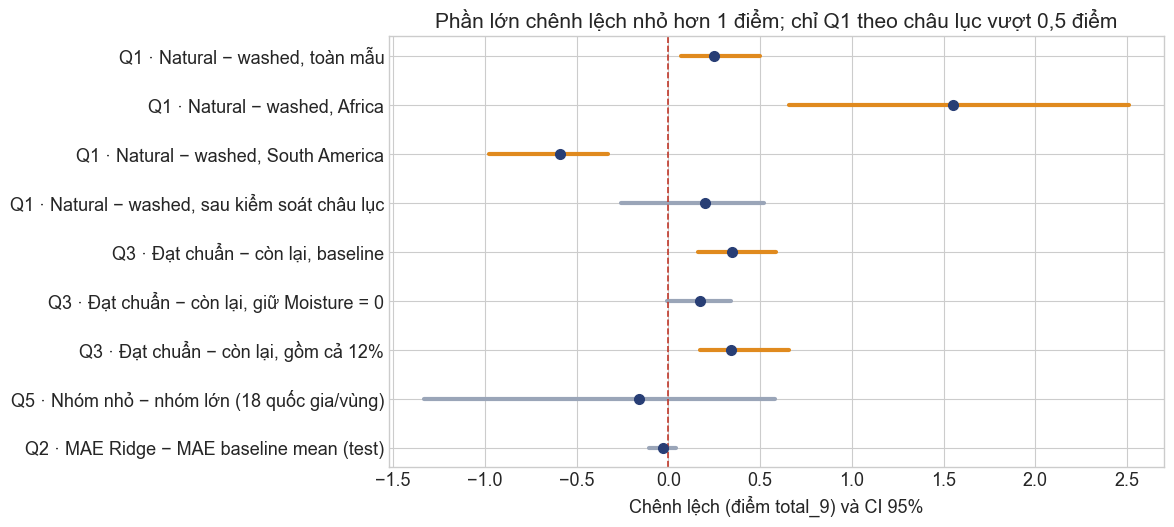

In [4]:
pts = key_estimates[key_estimates["Đơn vị"] == "điểm"].iloc[::-1].reset_index(drop=True)
labels = pts["Câu"] + " · " + pts["Ước lượng"]
colors = np.where(pts["CI chứa 0"], "#9AA5B8", "#E08A1E")

fig, ax = plt.subplots(figsize=(10, 5.6))
for i, row in pts.iterrows():
    ax.plot([row["CI thấp"], row["CI cao"]], [i, i], color=colors[i], linewidth=3, solid_capstyle="round")
    ax.plot(row["Giá trị"], i, "o", color="#283E75", markersize=7, zorder=3)
ax.axvline(0, color="#C0392B", linestyle="--", linewidth=1.2)
ax.set_yticks(range(len(pts)))
ax.set_yticklabels(labels)
ax.set_xlabel("Chênh lệch (điểm total_9) và CI 95%")
ax.set_title("Phần lớn chênh lệch nhỏ hơn 1 điểm; chỉ Q1 theo châu lục vượt 0,5 điểm")
plt.show()

**Nhận xét.** Chỉ có chênh lệch theo châu lục ở Q1 (Africa +1,55; South America −0,59) có độ lớn vượt 0,5 điểm. Các chênh lệch có CI không chứa 0 khác đều nằm trong khoảng 0,25–0,35 điểm, nhỏ so với độ lệch chuẩn của `total_9` (2,47 điểm trên tập train của Q2). Bốn ước lượng có CI chứa 0 gồm hai phiên bản đổi cách phân tích (Q1 sau kiểm soát châu lục, Q3 giữ `Moisture = 0`), Q5 chỉ có 18 quốc gia/vùng, và chênh lệch MAE của mô hình Q2 so với baseline.

<a id="s2"></a>
<div style="background-color:#283E75;color:#ffffff;padding:14px 24px;border-radius:8px;margin-top:24px">

<span style="font-size:17px;font-weight:700;letter-spacing:3px;color:#E3EBFA">PHẦN 2</span>

## <span style="color:#ffffff">Limitations</span>

<span style="font-size:15px;color:#DCE6F7">Hạn chế chung của dữ liệu và cách phân tích</span>

</div>

| Hạn chế | → Ảnh hưởng tới kết luận nào |
|:---|:---|
| **1. Mẫu nhỏ:** file chính có **1.339 lô** (`REC_ID` 0–1338, không phải 1.338). | Nhiều phép so sánh phải chia nhỏ mẫu nên CI rộng (xem hạn chế 8). |
| **2. Chỉ có lô được gửi cho CQI chấm** (thiên lệch chọn mẫu): nhà sản xuất tự chọn lô để gửi, thường là lô khá. | Mọi kết quả chỉ áp dụng cho lô tương tự, không cho cà phê đại trà hay toàn bộ sản lượng một quốc gia; điểm tập trung trong khoảng hẹp. |
| **3. 98% là Arabica** (1.311 / 1.339 lô; chỉ 28 lô Robusta, đã loại). | Không kết luận được gì cho Robusta. |
| **4. Thiếu biến quan trọng: độ cao, khí hậu, giá.** | Q1, Q3 không kiểm soát được các biến nhiễu này; có thể là lý do chính khiến mô hình Q2 không vượt baseline. |
| **5. `total_9` do nhóm tự tính** (tổng 9 thuộc tính, không có Cupper Points, không trừ điểm lỗi). | Không so trực tiếp với điểm CQI chính thức hay ngưỡng "≥ 80 là specialty". |
| **6. Dữ liệu quan sát.** | Mọi kết quả là liên hệ, không phải nhân quả (ví dụ không nói được "sấy về 10–12% làm tăng 0,34 điểm" hay "sơ chế khô làm tăng điểm"). |
| **7. 252 lô Arabica có `Moisture = 0`** (19,2% của 1.310 lô hợp lệ) là giá trị giữ chỗ cho dữ liệu thiếu. | Q3 nhạy với cách xử lý các lô này: giữ lại thì chênh lệch còn +0,17, CI chạm 0. |
| **8. Nhiều nhóm con ít lô:** natural ở Africa và Asia mỗi nơi 27 lô (Q1); 18 quốc gia/vùng (Q5); 86 lô năm 2017 (Q4); 269 lô test, năm 2018 chỉ 6 lô (Q2). | CI rộng; "chưa đủ bằng chứng" ở các nhóm này có thể do ít lô chứ không phải do không có khác biệt. |
| **9. Dữ liệu cũ** (thu hoạch 2009–2018). | Kết quả có thể không còn đúng với kỹ thuật sơ chế và cơ cấu nguồn cung hiện nay. |

<a id="s3"></a>
<div style="background-color:#283E75;color:#ffffff;padding:14px 24px;border-radius:8px;margin-top:24px">

<span style="font-size:17px;font-weight:700;letter-spacing:3px;color:#E3EBFA">PHẦN 3</span>

## <span style="color:#ffffff">Future work</span>

<span style="font-size:15px;color:#DCE6F7">Hướng mở rộng nếu có thêm thời gian và dữ liệu</span>

</div>

1. **Dữ liệu CQI mới hơn:** thu thập các lô được chấm sau 2018 để kiểm tra Q4 (xu hướng sau khi kiểm soát quốc gia) trên chuỗi thời gian dài hơn 6 năm và đánh giá lại mô hình Q2 trên các năm mới.
2. **Thêm độ cao và khí hậu:** nối thêm độ cao vùng trồng và dữ liệu khí hậu (nhiệt độ, lượng mưa theo vùng–năm) để kiểm soát biến nhiễu ở Q1, Q3 và làm feature cho Q2.
3. **Mô hình khác cho Q2:** thử gradient boosting, mô hình có hiệu ứng ngẫu nhiên theo quốc gia, và mở rộng lưới tinh chỉnh (RF và Ridge · A đang chọn giá trị ở biên lưới); vì tập test đã được dùng, cần một tập test mới (ví dụ dữ liệu CQI sau 2018) để đánh giá lại.
4. **Kiểm soát chi tiết hơn:** kiểm soát quốc gia thay vì châu lục ở Q1 (để kiểm tra giả thuyết vì sao South America ngược chiều) và dùng `Moisture` dạng liên tục kèm kiểm soát quốc gia ở Q3.

<a id="s4"></a>
<div style="background-color:#283E75;color:#ffffff;padding:14px 24px;border-radius:8px;margin-top:24px">

<span style="font-size:17px;font-weight:700;letter-spacing:3px;color:#E3EBFA">PHẦN 4</span>

## <span style="color:#ffffff">Individual reflection</span>

<span style="font-size:15px;color:#DCE6F7">Mỗi thành viên tự viết phần của mình</span>

</div>

<span style="color:#5B6B8C;font-size:14px">Mỗi phần cần đủ 4 ý: <b>khó khăn</b> gặp phải, <b>cách vượt qua</b>, <b>bài học</b>, và <b>cách đã dùng LLM</b> (khớp với <code>LLM_USAGE.md</code>).</span>

### <span style="color:#283E75">▍Đặng Ngọc Hoàng (24120053)</span>

- **Khó khăn:** *(thành viên tự viết)*
- **Cách vượt qua:** *(thành viên tự viết)*
- **Bài học:** *(thành viên tự viết)*
- **Cách dùng LLM:** *(thành viên tự viết)*

### <span style="color:#283E75">▍Đào Đức Thịnh (23120361)</span>

- **Khó khăn:** *(thành viên tự viết)*
- **Cách vượt qua:** *(thành viên tự viết)*
- **Bài học:** *(thành viên tự viết)*
- **Cách dùng LLM:** *(thành viên tự viết)*

### <span style="color:#283E75">▍Nguyễn Mai Tùng Hiếu (24120311)</span>

- **Khó khăn:** *(thành viên tự viết)*
- **Cách vượt qua:** *(thành viên tự viết)*
- **Bài học:** *(thành viên tự viết)*
- **Cách dùng LLM:** *(thành viên tự viết)*